# Homework 2: Pennsylvania HAND Model

## 1. Download Pennsylvania DEM tiles

In [60]:
from pathlib import Path
PROJECT_DIR = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "assignments").is_dir()), Path.cwd().resolve()
)
ASSIGNMENT_DIR = PROJECT_DIR / "assignments" / "homework2"

import requests
import os
import math
import geopandas as gpd
from shapely.geometry import box

### Tile names

In [61]:
def get_tile_name(lat, lon):

    lat_tile = f"n{int(abs(lat)):02d}" if lat >= 0 else f"s{int(abs(lat)):02d}"
    lon_tile = f"w{int(abs(lon)):03d}" if lon < 0 else f"e{int(abs(lon)):03d}"
    return f"{lat_tile}{lon_tile}"

lat, lon = 39.95, -75.16

tile_name = get_tile_name(math.ceil(lat), math.floor(lon))
print("DEM Tile Name:", tile_name)

DEM Tile Name: n40w076


### Bounding-box tiles

In [62]:
def get_tiles_in_bbox(min_lat, max_lat, min_lon, max_lon):

    tile_list = []
    for lat in range(math.floor(min_lat) + 1, math.ceil(max_lat) + 1):
        for lon in range(math.floor(min_lon), math.ceil(max_lon)):
            tile_list.append(get_tile_name(lat, lon))
    return tile_list

### Select Pennsylvania tiles

In [63]:
boundary_url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
boundary_file = str(ASSIGNMENT_DIR / "homework2-output/boundary/states.zip")

if not os.path.exists(boundary_file):
    os.makedirs(os.path.dirname(boundary_file), exist_ok=True)
    response = requests.get(boundary_url, timeout=120)
    response.raise_for_status()
    with open(boundary_file, "wb") as file:
        file.write(response.content)

states = gpd.read_file(boundary_file)
pa = states[states["STUSPS"] == "PA"].to_crs("EPSG:4326")
min_lon, min_lat, max_lon, max_lat = pa.total_bounds
tiles = get_tiles_in_bbox(min_lat, max_lat, min_lon, max_lon)

pa_tiles = []
for tile in tiles:
    lat = int(tile[1:3])
    lon = -int(tile[4:7])
    tile_boundary = box(lon, lat - 1, lon + 1, lat)
    if pa.geometry.iloc[0].intersection(tile_boundary).area > 0:
        pa_tiles.append(tile)

tiles = pa_tiles
print("Tiles to Download:", tiles)
print("Number of tiles:", len(tiles))

Tiles to Download: ['n40w081', 'n40w080', 'n40w079', 'n40w078', 'n40w077', 'n40w076', 'n41w081', 'n41w080', 'n41w079', 'n41w078', 'n41w077', 'n41w076', 'n41w075', 'n42w081', 'n42w080', 'n42w079', 'n42w078', 'n42w077', 'n42w076', 'n42w075', 'n43w081', 'n43w080', 'n43w079', 'n43w078', 'n43w077']
Number of tiles: 25


/opt/anaconda3/envs/geoai/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


### Download tiles

In [64]:
import requests
import os

def download_dem_1arc(tile_name, save_path="."):

    base_url = "https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/1/TIFF/current"
    url = f"{base_url}/{tile_name}/USGS_1_{tile_name}.tif"

    output_file = os.path.join(save_path, f"{tile_name}.tif")

    if os.path.exists(output_file):
        print("DEM tile already downloaded:", tile_name)
        return

    response = requests.get(url, stream=True, timeout=120)
    if response.status_code == 200:
        with open(output_file, "wb") as file:
            for chunk in response.iter_content(1024):
                file.write(chunk)
        print(f"DEM Tile {tile_name} downloaded successfully!")
    else:
        print(f"Error: Tile {tile_name} not found. Check availability.")
        print(url)

save_directory = str(ASSIGNMENT_DIR / "homework2-output/dem")
os.makedirs(save_directory, exist_ok=True)

for tile in tiles:
    download_dem_1arc(tile, save_directory)

DEM tile already downloaded: n40w081
DEM tile already downloaded: n40w080
DEM tile already downloaded: n40w079
DEM tile already downloaded: n40w078
DEM tile already downloaded: n40w077
DEM tile already downloaded: n40w076
DEM tile already downloaded: n41w081
DEM tile already downloaded: n41w080
DEM tile already downloaded: n41w079
DEM tile already downloaded: n41w078
DEM tile already downloaded: n41w077
DEM tile already downloaded: n41w076
DEM tile already downloaded: n41w075
DEM tile already downloaded: n42w081
DEM tile already downloaded: n42w080
DEM tile already downloaded: n42w079
DEM tile already downloaded: n42w078
DEM tile already downloaded: n42w077
DEM tile already downloaded: n42w076
DEM tile already downloaded: n42w075
DEM tile already downloaded: n43w081
DEM tile already downloaded: n43w080
DEM tile already downloaded: n43w079
DEM tile already downloaded: n43w078
DEM tile already downloaded: n43w077


### Verify downloads

In [65]:
import rasterio as rio

for tile in tiles:
    demfile = os.path.join(save_directory, f"{tile}.tif")
    with rio.open(demfile) as datasource:
        assert datasource.crs is not None
        assert datasource.count == 1
        datasource.read([1], window=next(datasource.block_windows(1))[1])

print("All selected DEM files are readable.")

All selected DEM files are readable.


## 2. HAND model for one tile

In [66]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from pysheds.grid import Grid
import pysheds
import numpy as np

### Detect pits

In [67]:
demfile = os.path.join(save_directory, f"{tiles[0]}.tif")

grid = Grid.from_raster(demfile)
dem = grid.read_raster(demfile)

pits = grid.detect_pits(dem)

In [68]:
grid.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- undefined
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

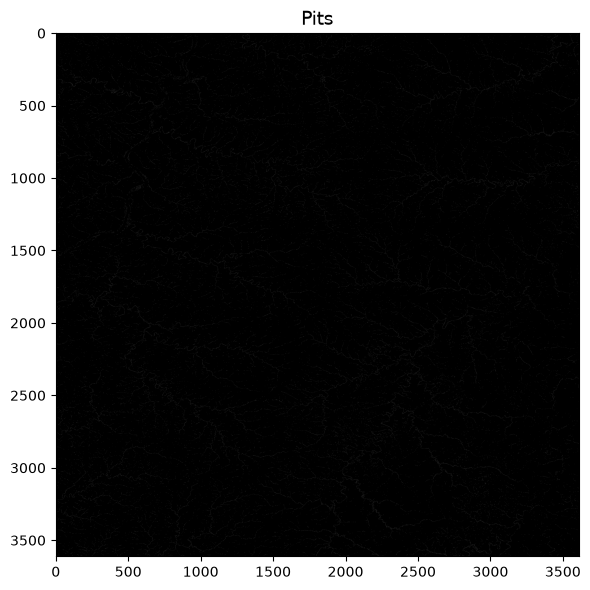

In [39]:
fig, ax = plt.subplots(figsize=(8,6))
fig.patch.set_alpha(0)

plt.imshow(pits, cmap='Greys_r', zorder=1)
plt.title('Pits', size=14)
plt.tight_layout()

### Fill pits

In [40]:
pit_filled_dem = grid.fill_pits(dem)
pits = grid.detect_pits(pit_filled_dem)
assert not pits.any()

### Detect depressions

In [41]:
depressions = grid.detect_depressions(pit_filled_dem)

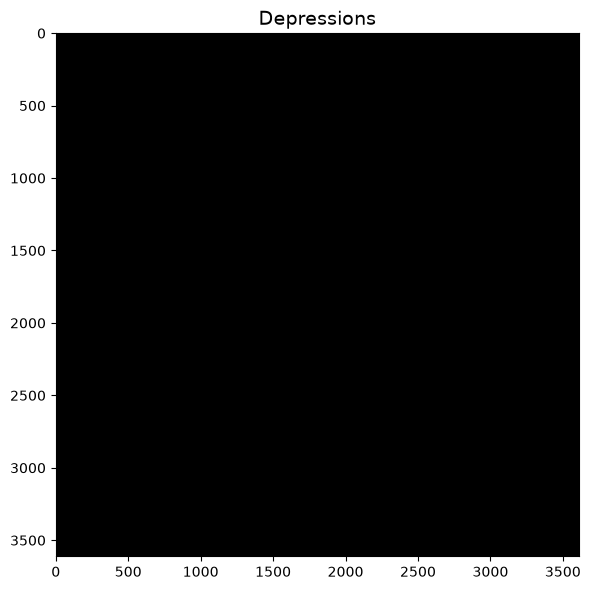

In [42]:
fig, ax = plt.subplots(figsize=(8,6))
fig.patch.set_alpha(0)

plt.imshow(depressions, cmap='Greys_r', zorder=1)
plt.title('Depressions', size=14)
plt.tight_layout()

### Fill depressions

In [43]:
flooded_dem = grid.fill_depressions(pit_filled_dem)
depressions = grid.detect_depressions(flooded_dem)
assert not depressions.any()

### Resolve flats

In [44]:
inflated_dem = grid.resolve_flats(flooded_dem)
flats = grid.detect_flats(inflated_dem)

### Flow direction and accumulation

In [45]:
fdir = grid.flowdir(inflated_dem)

acc = grid.accumulation(fdir)

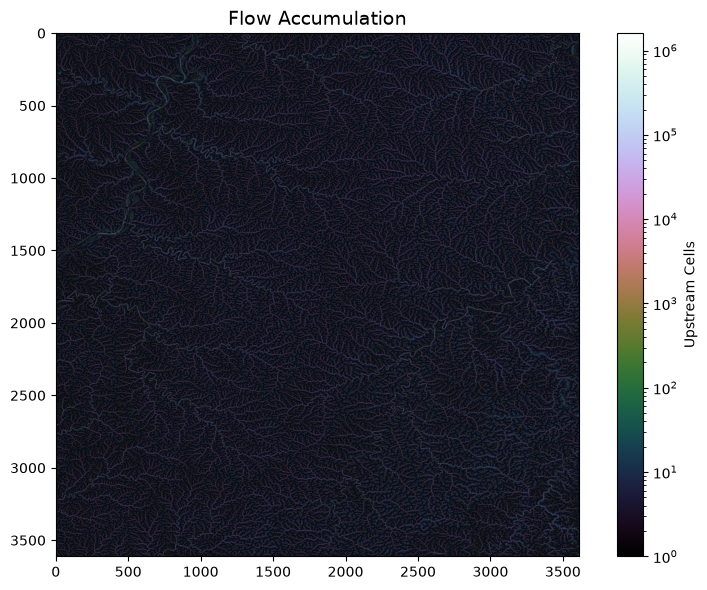

In [46]:
fig, ax = plt.subplots(figsize=(8,6))
fig.patch.set_alpha(0)
im = ax.imshow(acc, zorder=2,
               cmap='cubehelix',
               norm=colors.LogNorm(1, acc.max()),
               interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Upstream Cells')
plt.title('Flow Accumulation', size=14)
plt.tight_layout()

### Height above nearest drainage

In [47]:
hand = grid.compute_hand(fdir, dem, acc > 200)

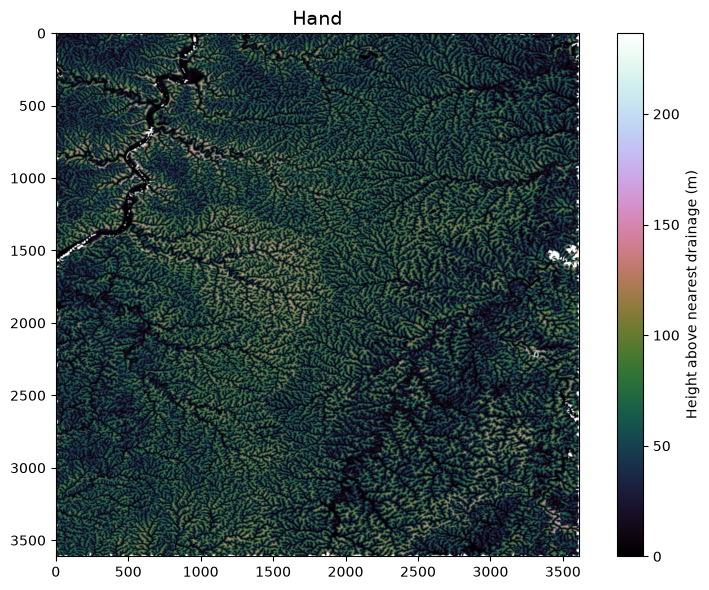

In [48]:
fig, ax = plt.subplots(figsize=(8,6))
fig.patch.set_alpha(0)
im = ax.imshow(hand, zorder=2,
               cmap='cubehelix',
               norm=colors.Normalize(0, max(1, np.nanmax(hand))),
               interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Height above nearest drainage (m)')
plt.title('Hand', size=14)
plt.tight_layout()

### Estimate inundation depth

In [49]:
threshold = 5
inundation_extent = np.where(hand < threshold, threshold - hand, np.nan)

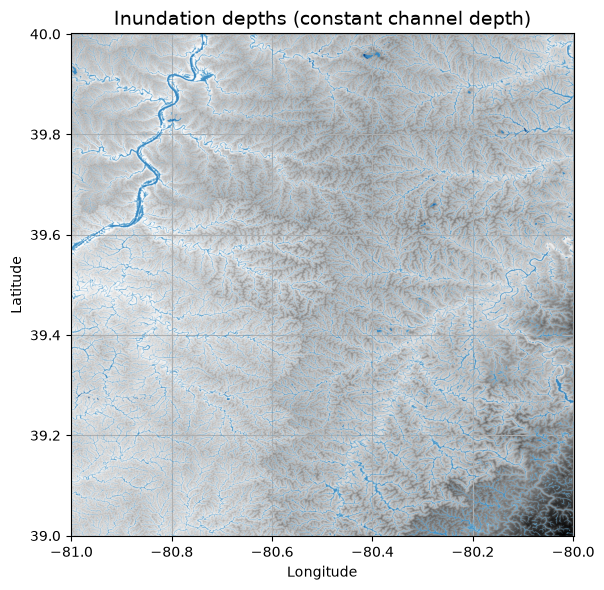

In [50]:
fig, ax = plt.subplots(figsize=(8,6))
fig.patch.set_alpha(0)
dem_view = grid.view(dem, nodata=np.nan, dtype=np.float64)
plt.imshow(dem_view, extent=grid.extent, cmap='Greys', zorder=1)
plt.imshow(inundation_extent, extent=grid.extent,
           cmap='Blues', vmin=-5, vmax=10, zorder=2)
plt.grid(zorder=0)
plt.title('Inundation depths (constant channel depth)', size=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()

### Export GeoTIFFs

In [51]:
import rasterio as rio

output_directory = str(ASSIGNMENT_DIR / "HAND_Results")
os.makedirs(output_directory, exist_ok=True)

with rio.open(demfile) as datasource:
    meta = datasource.meta

meta.update(dtype=rio.float32, compress='lzw', nodata=np.nan)

with rio.open(os.path.join(output_directory, f"{tiles[0]}_hand.tif"), 'w', **meta) as dst:
    dst.write(hand.astype(rio.float32), 1)

with rio.open(os.path.join(output_directory, f"{tiles[0]}_inundation.tif"), 'w', **meta) as dst:
    dst.write(inundation_extent.astype(rio.float32), 1)

## 3. Process all Pennsylvania tiles

In [52]:
inundation_files = []

for tile in tiles:
    print("Processing:", tile)
    demfile = os.path.join(save_directory, f"{tile}.tif")

    grid = Grid.from_raster(demfile)
    dem = grid.read_raster(demfile)

    pit_filled_dem = grid.fill_pits(dem)

    flooded_dem = grid.fill_depressions(pit_filled_dem)

    inflated_dem = grid.resolve_flats(flooded_dem)

    fdir = grid.flowdir(inflated_dem)

    acc = grid.accumulation(fdir)

    hand = grid.compute_hand(fdir, dem, acc > 200)

    threshold = 5
    inundation_extent = np.where(hand < threshold, threshold - hand, np.nan)

    with rio.open(demfile) as datasource:
        meta = datasource.meta
    meta.update(dtype=rio.float32, compress='lzw', nodata=np.nan)

    with rio.open(os.path.join(output_directory, f"{tile}_hand.tif"), 'w', **meta) as dst:
        dst.write(hand.astype(rio.float32), 1)

    output_file = os.path.join(output_directory, f"{tile}_inundation.tif")
    with rio.open(output_file, 'w', **meta) as dst:
        dst.write(inundation_extent.astype(rio.float32), 1)
    inundation_files.append(output_file)

    del grid, dem, pit_filled_dem, flooded_dem, inflated_dem, fdir, acc, hand, inundation_extent

print("Finished tiles:", len(inundation_files))

Processing: n40w081
Processing: n40w080
Processing: n40w079
Processing: n40w078
Processing: n40w077
Processing: n40w076
Processing: n41w081
Processing: n41w080
Processing: n41w079
Processing: n41w078
Processing: n41w077
Processing: n41w076
Processing: n41w075
Processing: n42w081
Processing: n42w080
Processing: n42w079
Processing: n42w078
Processing: n42w077
Processing: n42w076
Processing: n42w075
Processing: n43w081
Processing: n43w080
Processing: n43w079
Processing: n43w078
Processing: n43w077
Finished tiles: 25


## 4. Mosaic the inundation GeoTIFFs

In [69]:
from contextlib import ExitStack
from rasterio.merge import merge
from rasterio.features import geometry_mask
from rasterio.enums import Resampling

assert len(inundation_files) == len(tiles), "Some tiles have not been processed."
mosaic_file = os.path.join(output_directory, "PA_inundation_depth.tif")

with ExitStack() as stack:
    src_files = [stack.enter_context(rio.open(file)) for file in inundation_files]
    for datasource in src_files:
        assert datasource.crs == src_files[0].crs
        assert np.allclose(datasource.res, src_files[0].res)
    pa_mosaic = pa.to_crs(src_files[0].crs)
    merge(src_files, bounds=tuple(pa_mosaic.total_bounds), nodata=np.nan,
          method="first", dst_path=mosaic_file, mem_limit=128,
          dst_kwds={"compress": "lzw", "tiled": True, "blockxsize": 512,
                    "blockysize": 512, "BIGTIFF": "IF_SAFER"})

with rio.open(mosaic_file, "r+") as dst:
    for _, window in dst.block_windows(1):
        data = dst.read([1], window=window)
        data = np.reshape(data, data.shape[1:], copy=False)
        inside_pa = geometry_mask(pa_mosaic.geometry, out_shape=data.shape,
                                  transform=dst.window_transform(window), invert=True)
        data[~inside_pa] = np.nan
        dst.write(data, 1, window=window)
    dst.set_band_description(1, "Estimated inundation depth (m), 5 m channel-stage scenario")
    dst.build_overviews([2, 4, 8, 16], Resampling.nearest)

print("Pennsylvania GeoTIFF:", mosaic_file)

Pennsylvania GeoTIFF: HAND_Results/PA_inundation_depth.tif


## 5. Pennsylvania inundation map

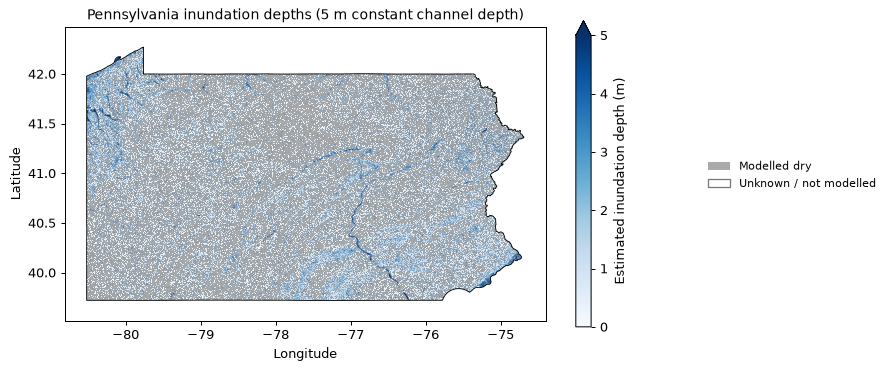

In [70]:
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from contextlib import ExitStack
from rasterio.merge import merge
from rasterio.features import geometry_mask

with rio.open(mosaic_file) as datasource:
    scale = max(datasource.width / 2000, datasource.height / 1200, 1)
    inundation_mosaic = datasource.read(
        [1], masked=True,
        out_shape=(1, max(1, int(datasource.height / scale)), max(1, int(datasource.width / scale))),
        resampling=Resampling.nearest
    )
    inundation_mosaic = np.reshape(inundation_mosaic, inundation_mosaic.shape[1:], copy=False)
    extent = (datasource.bounds.left, datasource.bounds.right,
              datasource.bounds.bottom, datasource.bounds.top)

with ExitStack() as stack:
    hand_sources = [stack.enter_context(rio.open(file.replace("_inundation.tif", "_hand.tif")))
                    for file in inundation_files]
    hand_mosaic, hand_transform = merge(
        hand_sources, bounds=(extent[0], extent[2], extent[1], extent[3]),
        res=((extent[1] - extent[0]) / inundation_mosaic.shape[1],
             (extent[3] - extent[2]) / inundation_mosaic.shape[0]),
        nodata=np.nan, method="first", resampling=Resampling.nearest
    )
inside_pa = geometry_mask(pa_mosaic.geometry, out_shape=inundation_mosaic.shape,
                          transform=hand_transform, invert=True)
dry = inside_pa & np.isfinite(hand_mosaic[0]) & (hand_mosaic[0] >= threshold)
dry &= np.ma.getmaskarray(inundation_mosaic)

fig, ax = plt.subplots(figsize=(10, 6), dpi=90)
fig.patch.set_alpha(0)
ax.imshow(np.ma.masked_where(~dry, np.ones(dry.shape)), extent=extent,
          cmap=ListedColormap(['#aaaaaa']), interpolation='nearest', zorder=1)
im = plt.imshow(inundation_mosaic, extent=extent, cmap='Blues',
                vmin=0, vmax=threshold, zorder=2)
pa_mosaic.boundary.plot(ax=ax, color='black', linewidth=0.7, zorder=3)
minx, miny, maxx, maxy = pa_mosaic.total_bounds
xpad = (maxx - minx) * 0.05
ypad = (maxy - miny) * 0.08
ax.set_xlim(minx - xpad, maxx + xpad)
ax.set_ylim(miny - ypad, maxy + ypad)
plt.colorbar(im, ax=ax, label='Estimated inundation depth (m)', extend='max', shrink=0.6)
plt.title('Pennsylvania inundation depths (5 m constant channel depth)', size=11)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
fig.legend(
    handles=[Patch(facecolor='#aaaaaa', label='Modelled dry'),
             Patch(facecolor='white', edgecolor='#777', label='Unknown / not modelled')],
    loc='center left', bbox_to_anchor=(0.78, 0.5), frameon=False, fontsize=9
)
fig.tight_layout(rect=(0, 0, 0.76, 1))
plt.savefig(os.path.join(output_directory, "PA_inundation_map.png"), dpi=200, bbox_inches="tight")
plt.show()

### Result checks

In [71]:
inundated_pixels = 0
above_stage_pixels = 0
maximum_depth = 0.0

with rio.open(mosaic_file) as datasource:
    for _, window in datasource.block_windows(1):
        data = datasource.read([1], window=window, masked=True)
        data = np.reshape(data, data.shape[1:], copy=False)
        inundated_pixels += int(np.ma.filled(data > 0, False).sum())
        above_stage_pixels += int(np.ma.filled(data > threshold, False).sum())
        if data.count():
            maximum_depth = max(maximum_depth, float(data.max()))

print("Processed tiles:", len(inundation_files), "of", len(tiles))
print("Positive-depth pixels:", inundated_pixels)
print("Maximum depth (m):", maximum_depth)
print("Pixels deeper than the assumed channel stage:", above_stage_pixels)
assert inundated_pixels > 0, "The mosaic has no positive depths; inspect the tile results."

Processed tiles: 25 of 25
Positive-depth pixels: 33825413
Maximum depth (m): 122.525634765625
Pixels deeper than the assumed channel stage: 494219


## 6. Report

# Pennsylvania Flood Mapping with HAND

For this assignment, I used USGS elevation data to estimate inundation depths across Pennsylvania. I used the Census 2024 state boundary to identify the 25 DEM tiles needed to cover the state.

## What I did
I followed the Pennsylvania example in the course notebook. I filled pits and depressions in the elevation data and resolved flat areas before calculating flow direction and accumulation. I then calculated HAND, or height above nearest drainage, using the original DEM. I used an accumulation threshold of 200 cells to identify drainage cells and assumed a 5 m channel stage.

Where HAND was below 5 m, I calculated inundation depth by subtracting HAND from 5. I used a loop to process all the tiles and saved the HAND and inundation results as GeoTIFFs. I then combined the inundation tiles into one statewide GeoTIFF and clipped it to Pennsylvania. I kept the original 1-arc-second grid and coordinate system (EPSG:4269).

## Results
- Tiles processed: **25 out of 25**.
- Cells with a positive inundation depth: **33,825,413**.
- Maximum calculated depth: **122.53 m**.
- Cells with depths above the assumed 5 m stage: **494,219**.



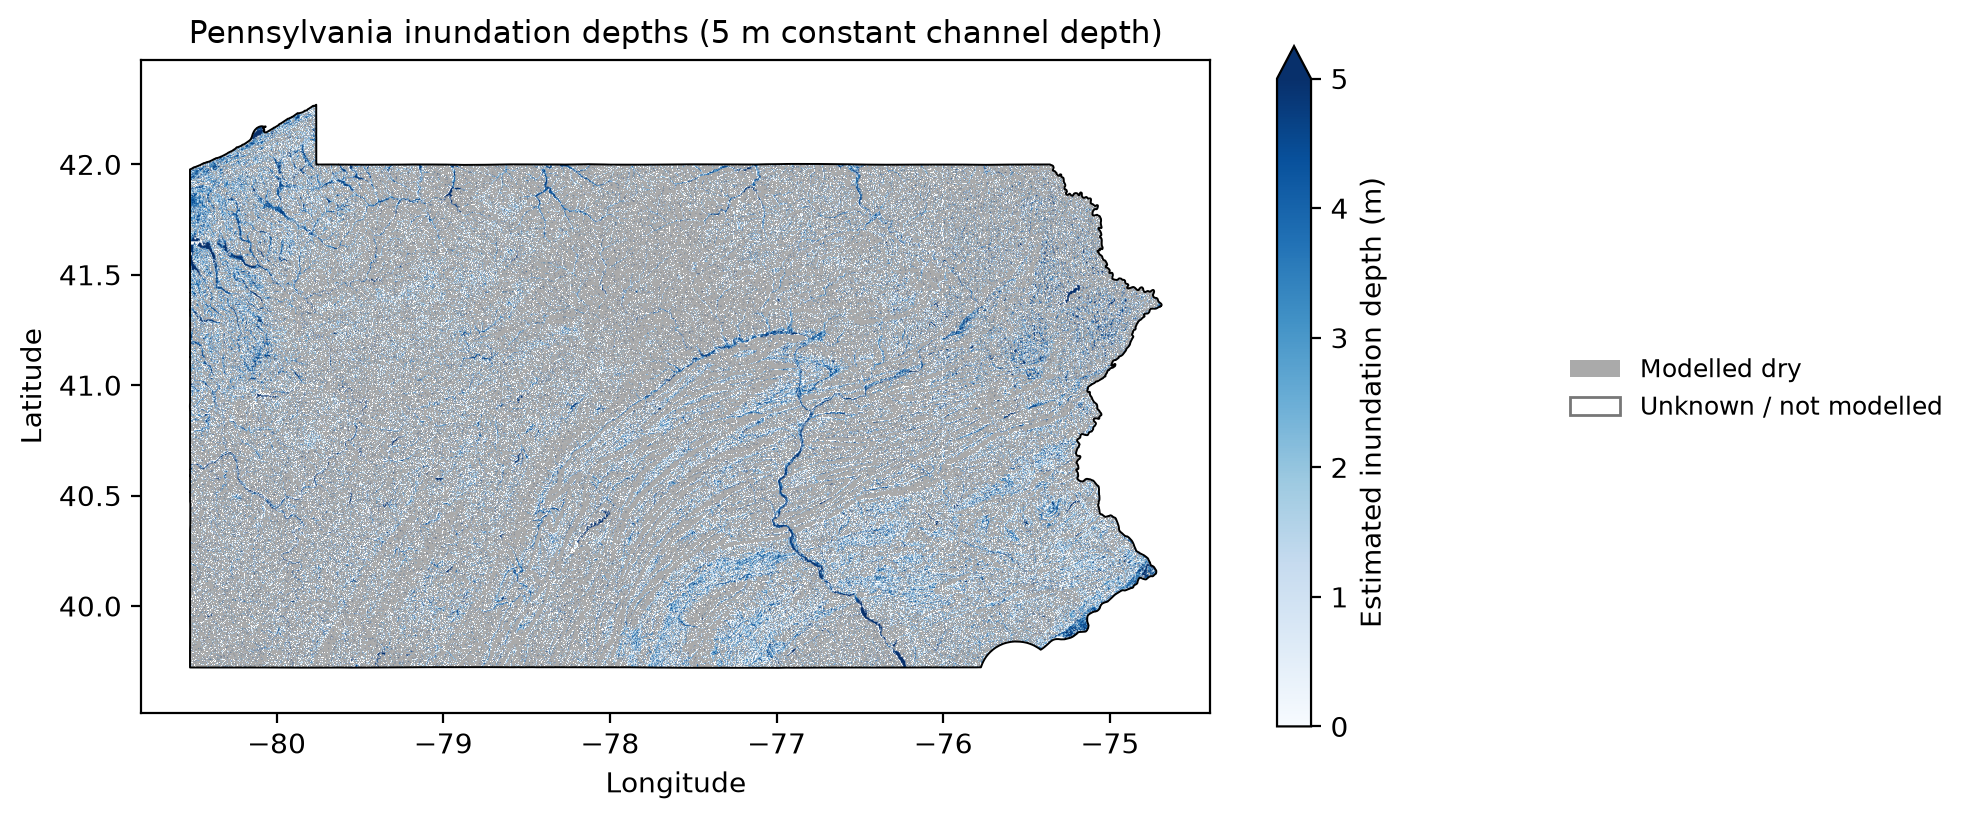



The blue areas show estimated inundation depths and follow a branching drainage pattern across the state. Gray shows areas classified as dry. White areas within Pennsylvania have no depth or dry classification.

## Limits of the results
The example saves both dry and unknown cells as missing values (NaN) in the depth GeoTIFF. I used the separate HAND files to tell them apart on the map. Each tile was processed separately, so flow paths stop at tile boundaries. Combining the tiles into one image does not fix this and can leave visible seams.

Some calculated depths exceed the 5 m stage because the original ground elevation is below the drainage reference assigned by the model. The maximum of 122.53 m is a model result, not a measured flood depth. This map shows what the example produces under an assumed water level; it does not predict a specific flood event.

## Files and sources
- Statewide GeoTIFF: `PA_inundation_depth.tif`.
- Tile results: `*_hand.tif` and `*_inundation.tif`.
- [USGS 3DEP](https://apps.nationalmap.gov/downloader/).
- [Census 2024 state boundary](https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip).
- Course notebooks: `download-dem.ipynb` and `urban-flood-vulnerability.ipynb`.


In [73]:
from IPython.display import Markdown, Image, display

report = f"""# Pennsylvania Flood Mapping with HAND

For this assignment, I used USGS elevation data to estimate inundation depths across Pennsylvania. I used the Census 2024 state boundary to identify the {len(tiles)} DEM tiles needed to cover the state.

## What I did
I followed the Pennsylvania example in the course notebook. I filled pits and depressions in the elevation data and resolved flat areas before calculating flow direction and accumulation. I then calculated HAND, or height above nearest drainage, using the original DEM. I used an accumulation threshold of 200 cells to identify drainage cells and assumed a {threshold} m channel stage.

Where HAND was below {threshold} m, I calculated inundation depth by subtracting HAND from {threshold}. I used a loop to process all the tiles and saved the HAND and inundation results as GeoTIFFs. I then combined the inundation tiles into one statewide GeoTIFF and clipped it to Pennsylvania. I kept the original 1-arc-second grid and coordinate system (EPSG:4269).

## Results
- Tiles processed: **{len(inundation_files)} out of {len(tiles)}**.
- Cells with a positive inundation depth: **{inundated_pixels:,}**.
- Maximum calculated depth: **{maximum_depth:.2f} m**.
- Cells with depths above the assumed {threshold} m stage: **{above_stage_pixels:,}**.

![Pennsylvania inundation depths](PA_inundation_map.png)

The blue areas show estimated inundation depths and follow a branching drainage pattern across the state. Gray shows areas classified as dry. White areas within Pennsylvania have no depth or dry classification.

## Limits of the results
The example saves both dry and unknown cells as missing values (NaN) in the depth GeoTIFF. I used the separate HAND files to tell them apart on the map. Each tile was processed separately, so flow paths stop at tile boundaries. Combining the tiles into one image does not fix this and can leave visible seams.

Some calculated depths exceed the {threshold} m stage because the original ground elevation is below the drainage reference assigned by the model. The maximum of {maximum_depth:.2f} m is a model result, not a measured flood depth. This map shows what the example produces under an assumed water level; it does not predict a specific flood event.

## Files and sources
- Statewide GeoTIFF: `PA_inundation_depth.tif`.
- Tile results: `*_hand.tif` and `*_inundation.tif`.
- [USGS 3DEP](https://apps.nationalmap.gov/downloader/).
- [Census 2024 state boundary]({boundary_url}).
- Course notebooks: `download-dem.ipynb` and `urban-flood-vulnerability.ipynb`.
"""

report_file = os.path.join(output_directory, "PA_HAND_report.md")
with open(report_file, "w") as file:
    file.write(report)
report_before_map, report_after_map = report.split("![Pennsylvania inundation depths](PA_inundation_map.png)")
display(Markdown(report_before_map))
display(Image(filename=os.path.join(output_directory, "PA_inundation_map.png"), width=800))
display(Markdown(report_after_map))

import base64
from markdown_it import MarkdownIt

with open(os.path.join(output_directory, "PA_inundation_map.png"), "rb") as file:
    map_image = base64.b64encode(file.read()).decode()
report_html = MarkdownIt().render(report)
report_html = report_html.replace('src="PA_inundation_map.png"',
                                  f'src="data:image/png;base64,{map_image}"')
with open(os.path.join(output_directory, "PA_HAND_report.html"), "w") as file:
    file.write('<!doctype html><html lang="en"><meta charset="utf-8">'
               '<title>Pennsylvania HAND report</title>'
               '<style>body{font:16px/1.6 Arial;max-width:1000px;margin:40px auto;'
               'padding:0 24px}img{max-width:100%}</style><body>'
               + report_html + '</body></html>')